# CounterFlowFlame  

## Types of Combustion

-_Non-premixed combustion_, also known as diffusion combustion, is a type of combustion process where fuel and oxidizer (usually air) are not mixed thoroughly before ignition. 

-_Premixed combustion_,is a type of combustion process where fuel and air are intimately mixed before ignition.   
-Non-premixed combustion involves the separate introduction of fuel and oxidizer into the combustion zone, allowing them to mix and react as they flow into the reaction zone.

## Key characteristics of non-premixed combustion 

1. _Fuel and Oxidizer Separation_: In non-premixed combustion, fuel and oxidizer are introduced separately into the combustion chamber.  
2. _Flame Structure_: Non-premixed combustion typically results in a diffusion flame. In a diffusion flame, the fuel and oxidizer mix and react as they come into contact with each other in the combustion zone.  
3. _Temperature and Mixing Gradients_: Due to the gradual mixing of fuel and oxidizer in non-premixed combustion, temperature and composition gradients are often present in the combustion zone. These gradients can lead to various chemical reactions occurring at different locations within the flame, 


## Non-premixed combustion

Figure 1(a) illustrates a sketch of a laboratory counterflow (CF) burner configuration for non-premixed flames. In this canonical flame configuration fuel and oxidizer are supplied separately from two opposed nozzles, forming a stagnation flow. Within the opposed jet flow, mixing of fuel and oxidizer takes place and a reaction zone establishes at the location of near stoichiometric conditions. In this region, as highlighted in Fig.1(b) showing the principle one-dimensional flame structure at the symmetry axis along the spatial coordinate x, the maximum temperature and heat release (_ω˙<sub>T</sub>_) can be found. Furthermore, the fuel (_Y<sub>f</sub>_) and oxidizer species mass fractions (_Y<sub>ox</sub>_) are consumed, while the combustion products (_Y<sub>p</sub>_) are formed. Outside of the reaction zone, in the absence of chemical reactions, only mixing of burnt products against fuel-lean and fuel-rich conditions occurs. The mixing processes in non-premixed flames are characterized by the mixture fraction _Z_ and the corresponding spatial profile of _Z_, which monotonically increases from oxidizer to fuel side across the flame is also shown in Fig.1(b). In non-premixed flames, the mixture fraction serves as conditioning variable and the corresponding flame structure in mixture fraction space is shown in Fig.1(c). In this conditional representation of the flame, the reaction zone and the diffusive layers within the fuel-lean and fuel-rich regions are stretched, while the regions where the mixture does not significantly change is restricted to regions near the boundaries.

![](../Figures/cf/cf1.jpeg)

source : [Large Eddy simulation of turbulent Multi-regime combution](https://hessenbox.tu-darmstadt.de/download/MkJmZkJubmZQUjM2ZlJSVGEyN1h4/01_DiffusionFlame/popp_phd_2020.pdf?inline)

### Setting-up a CounterFlowFlame for Detailed-Chemistry model


## 1. Pre-processing

### _0 directory_
OpenFOAM uses a directory structure to organize various files and data for a simulation, and the "0" directory is where the initial conditions for your simulation are specified.

Update all the files in 0 directory with new boundary conditions,  

![](../Figures/cf/cf2.png)

  
In the context of the CounterFlow case, we have defined four distinct patches within the computational domain, each serving a specific role in the simulation:

Fuel Patch (Inlet for Methane):
This patch is designated as the "Fuel" patch, representing the inlet for methane, the primary fuel for the combustion simulation. Methane, as the fuel, enters the system through this patch.

Air Patch (Inlet for Oxidizer):
This patch is referred to as the "Air" patch, symbolizing the inlet for the oxidizer (typically air). The oxidizer, crucial for combustion, is introduced into the system through this patch.

FrontAndBack Patch (Outlet for Combustion):
Named "FrontAndBack," this patch is strategically placed to represent the outlet for the combustion process occurring within the simulation. Combustion products and other relevant outputs exit the system through this patch.

TopAndBottom Patch:
The "TopAndBottom" patch is designed to serve specific purposes related to the simulation context. Depending on the simulation scenario, it may be utilized for specific boundary conditions or as a region of interest within the simulation.

The reaction taking place in this simulation CH4 combusting with O2 creating CO2 and H2O. N2 is 
the non-reacting species. The boundary conditions and initial value of all species should be defined 
in the 0 directory. These values are mass fractions (between 0 and 1) and dimension less, e.g. CH4:

_<span style="color: blue;">NOTE</span>
: If the file for a species does not exist in the 0 directory, the values from Ydefault will be used 
for that species._

### _constant directory_
The constant directory in OpenFOAM is a designated directory within a case that contains settings that remain constant throughout the simulation. It includes files related to geometry, initial conditions, turbulence models, and boundary conditions.  
In the thermophysicalProperties file the physical properties of the species can be set:

<pre>// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

thermoType
{
    type            heRhoThermo;
    mixture         reactingMixture;
    transport       sutherland;
    thermo          janaf;
    energy          sensibleEnthalpy;
    equationOfState perfectGas;
    specie          specie;
}

inertSpecie N2;

chemistryReader foamChemistryReader;
foamChemistryFile "<constant>/foam/reactions.foam";
foamChemistryThermoFile "<constant>/foam/thermo.foam";


// ************************************************************************* //</pre>

The mixture type is set to a reacting mixture for calculating the mixture properties and the heat 
capacities are calculated using “janaf polynomials”.  
'heRhoThermo' is a thermodynamic model in OpenFOAM designed for compressible, variable-density flows with the ability to handle mixtures of chemical species and consider sensible enthalpy effects.    
N2 is defines as inertSpecie. In reaction solvers in OpenFOAM<sup>®</sup> the inert specie is calculated 
explicitly using the mass balance equation (to satisfy mass conservation).

The species and the reactions are addressed using foamChemistryFile. In this simulation 
reactions and species are read from reactions file in the constant directory:

<pre>species
(
    O2
    H2O
    CH4
    CO2
    N2
);

reactions
{
    methaneReaction
    {
        type     irreversibleArrheniusReaction;
        reaction "CH4 + 2O2 = CO2 + 2H2O";
        A        5.2e16;
        beta     0;
        Ta       14906;
    }
}</pre>

_<span style="color: blue;">NOTE</span>
: Also the elements are listed in the reactions file and an element balance is 
performed in the calculations!_

In this simulation, we consider a mixture of several species, including O2, H2O, CH4, CO2, and N2. These species are defined in the species sub-dictionary. Additionally, within the reactions sub-dictionary, we specify various chemical reactions. One of the reactions we define is the combustion of methane, which is characterized as an irreversibleArrheniusReaction.


The coefficients of each 
species are defined in the _foamChemistryThermoFile_, which reads the file _thermos.compressibleGas_
from the constant directory (this step is outlined in the thermophysicalProperties file). For example, 
the O2 coefficients for each model are shown below:

<pre>// * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * //

O2
{
    specie
    {
        molWeight       31.9988;
    }
    elements
    {
        O       2;
    }
    thermodynamics
    {
        Tlow            200;
        Thigh           5000;
        Tcommon         1000;        highCpCoeffs    ( 3.69758 0.00061352 -1.25884e-07 1.77528e-11 -1.13644e-15 -1233.93 3.18917 );        lowCpCoeffs     ( 3.21294 0.00112749 -5.75615e-07 1.31388e-09 -8.76855e-13 -1005.25 6.03474 );
    }
    transport
    {
        As              1.67212e-06;
        Ts              170.672;
    }
}</pre>
  
  
_<span style="color: blue;">NOTE</span>
:  Number of elements in the specie is listed in this file!_  

### _system directory_
The system subdirectory within constant holds files related to the simulation control, such as solvers, tolerances, time-stepping settings, and physical models.

![](../Figures/cf/cf3.png)

By setting the adjustTimeStep to yes in the controlDict, the solver automatically ignores 
deltaT, and calculates the deltaT based on the maximum Courant number maxCo defined for it. 
Change the endTime to 0.25 and writeInterval to 0.025, to write every 0.025 s to case directory.

blockmesh: It has the Mesh data. Within the polyMesh, there's blockMeshDict which defines the scaling factor for the mesh. Here, it is set to 1. 
It also Lists each vertices by (x,y,z) coordinates, there are 8 vertices listed which represent a cuboid. It specifies the structures of block using the vertices with x, y, z extending from 0 -> 0.02, -0.01 -> 0.01, -0.01 -> 0.01, respectively.
In this case there are four boundary patches :
![](../Figures/cf/cf4.png)

### 2. Running Simulation

<pre>>blockMesh</pre> 
blockMesh command is used to mesh the case, After converting the mesh, check the boundary file in the constant/polyMesh directory

to start the simulation run use - <pre>>reactingFoam</pre> 
command reactingFoam is basically used in combustion process. It models the combustion of fuel with oxidizer and tracks the combustion products.

### 3. Post-processing 

The simulation results at 120 s are as follows:

In [2]:
import pyvista as pv
from matplotlib import pyplot as plt
reader = pv.POpenFOAMReader('/WORK_OF/skota/counterFlowFlame2D_cluster/foam.foam') # path to foam file
reader.case_type='reconstructed' #use 'decomposed' for decomposed cases
reader.set_active_time_value(0.25) #give a correct time value
fields = reader.read()['internalMesh']
fields
line = fields.sample_over_line((0,0,0),(0.02,0,0),resolution=100) # point one, point 2
line

PolyData (0x7f6edb797ee0)
  N Cells:    1
  N Points:   101
  N Strips:   0
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   0.000e+00, 0.000e+00
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   32

In [ ]:
print(line.points)
print(line.points[:,1])
print(line.points[:,2])


PolyData (0x7f6ece3f4be0)
  N Cells:    16000
  N Points:   16281
  N Strips:   0
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   -1.000e-02, 1.000e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   32

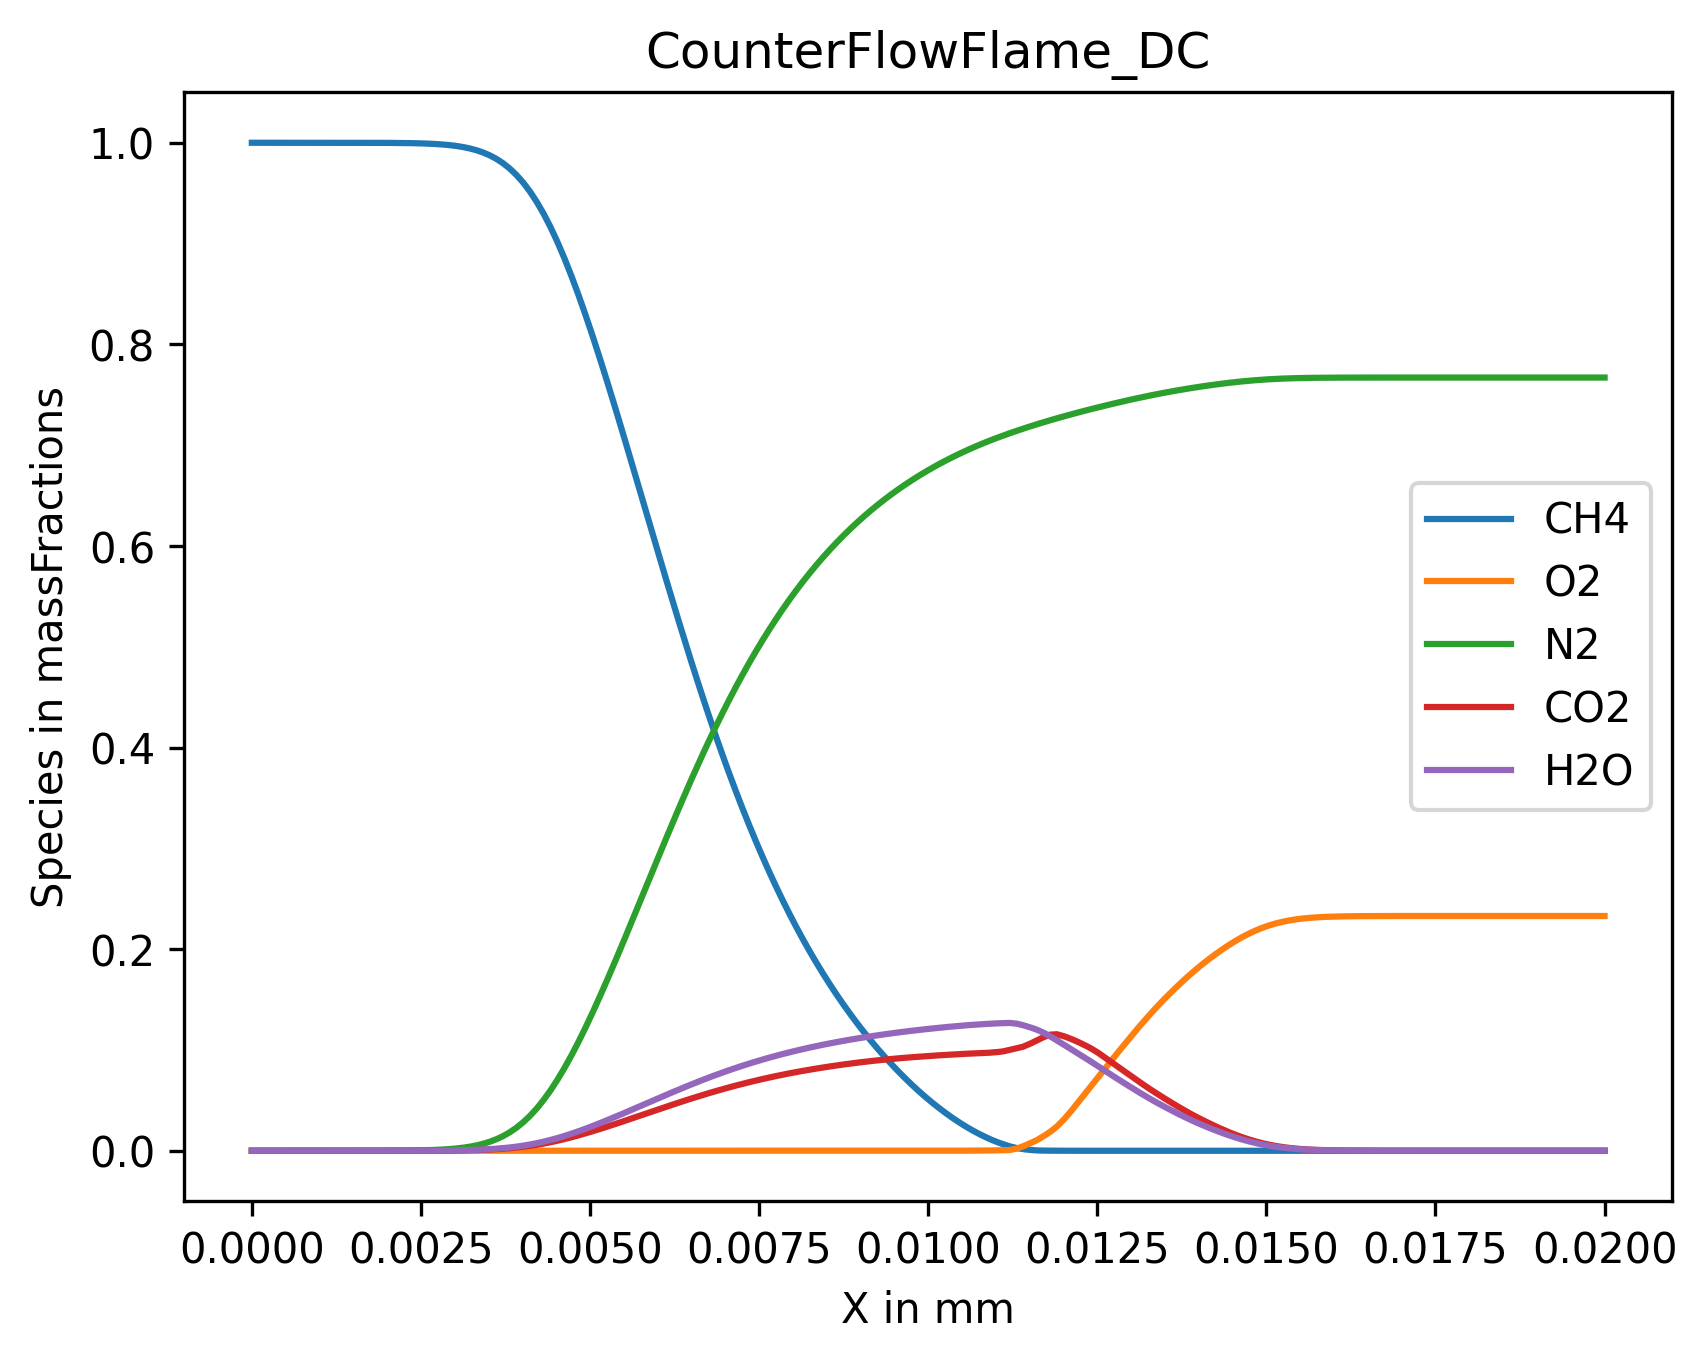

In [43]:
fig, ax = plt.subplots()
fig.set_dpi(300)
ax.plot(line.points[:,0],line['CH4'],label='CH4')
ax.plot(line.points[:,0],line['O2'],label='O2')
ax.plot(line.points[:,0],line['N2'],label='N2')
ax.plot(line.points[:,0],line['CO2'],label='CO2')
ax.plot(line.points[:,0],line['H2O'],label='H2O')
ax.set_xlabel('X in mm')
ax.set_ylabel('Species in massFractions')
ax.set_title('CounterFlowFlame_DC')
ax.legend()
slice = fields.slice((0,0,1),(0,0,0)) # origin vector, normal vector
slice

/tmp/ipykernel_15923/3016941282.py:12: UserWarning: The following kwargs were not used by contour: 'triangles'
  tricont = ax.tricontourf(pts[:,0], pts[:,1],  # pts X and Y in 2 D plot, depends on orientation of slice, for normal vector (0,0,1) use pts[:,0], pts[:,1]; for (0,1,0) use pts[:,0],pts[:,2]; (1,0,0) use pts[:,1],pts[:,2]


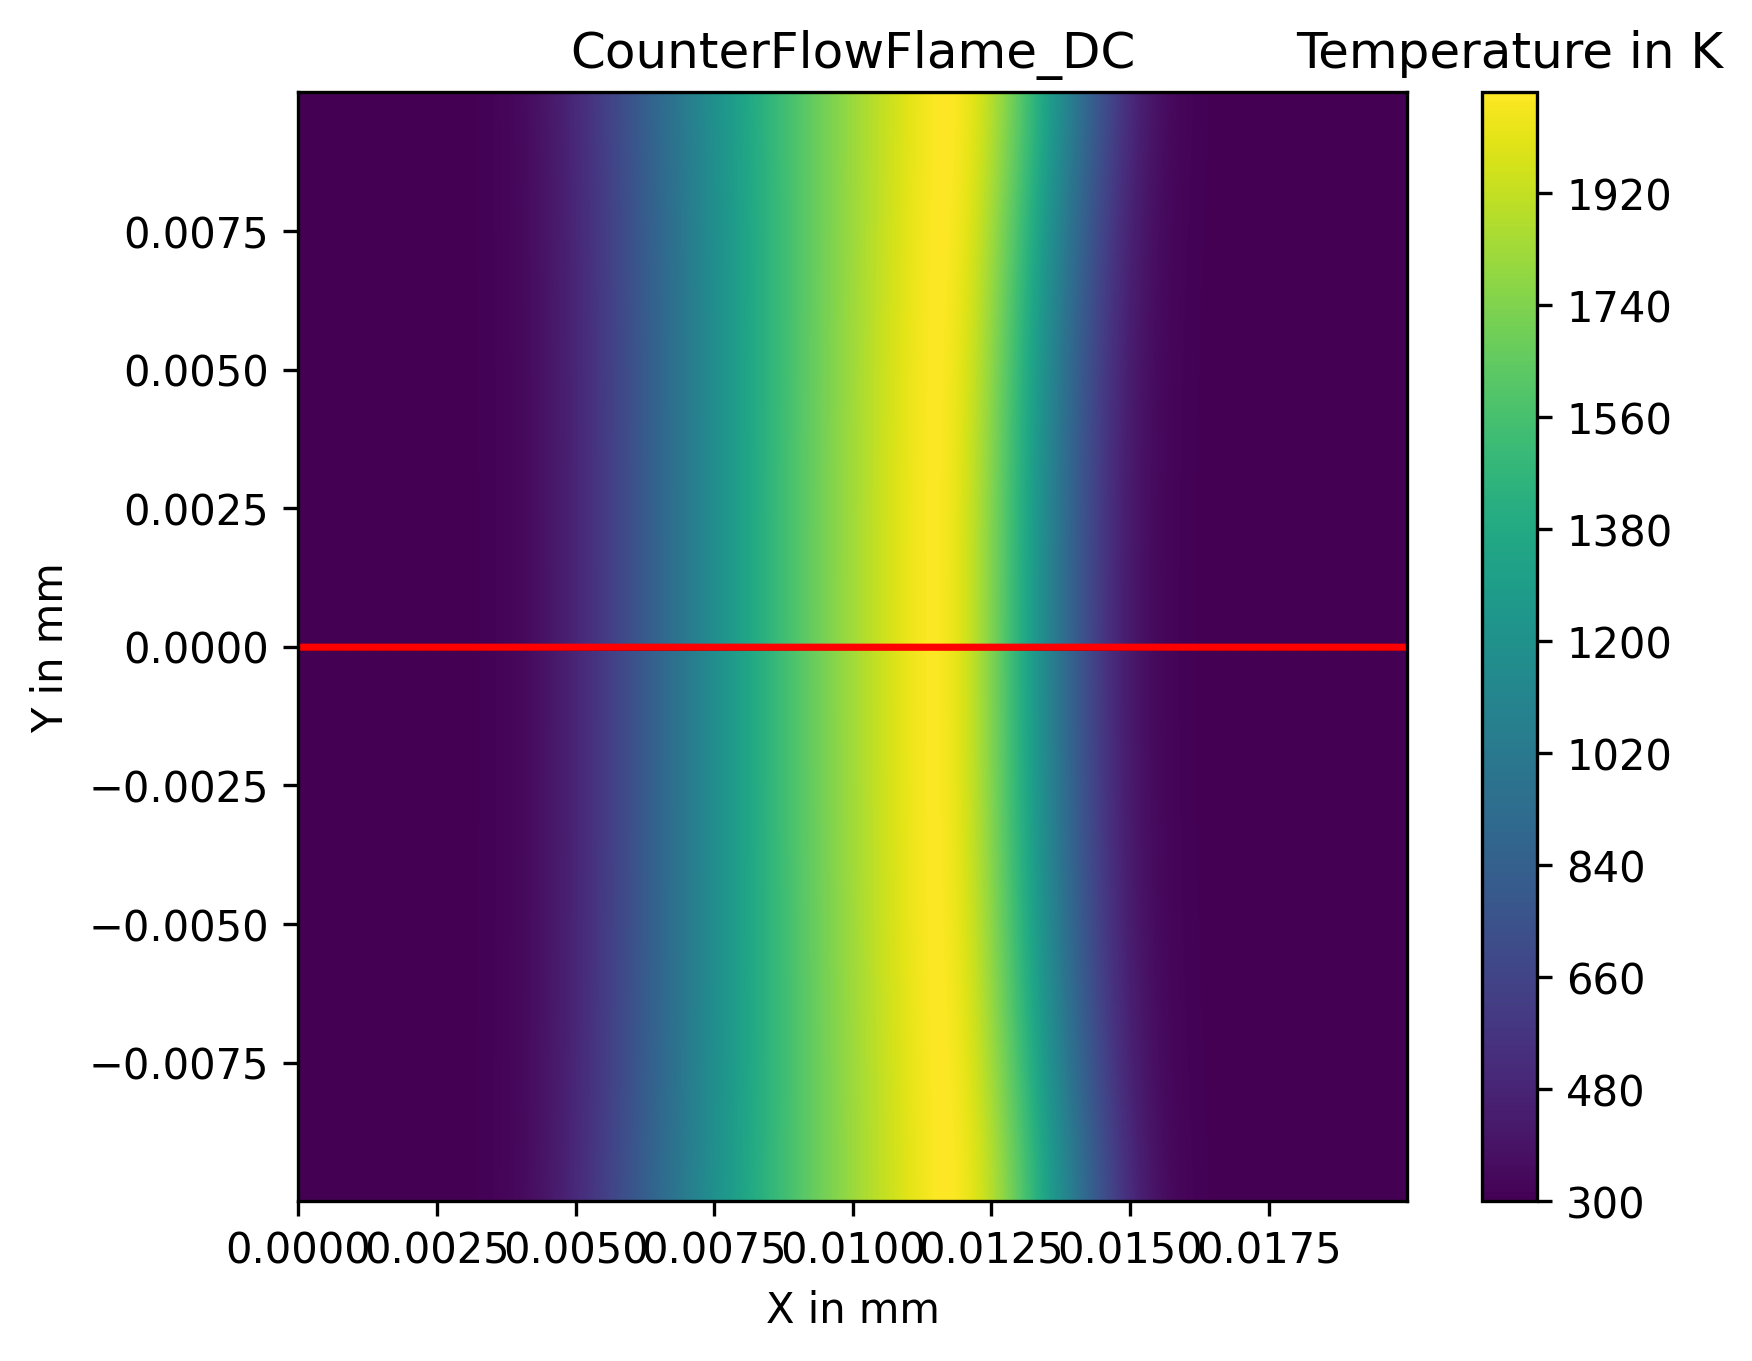

In [4]:
fig, ax = plt.subplots()
fig.set_dpi(300)
# prepare for plotting
plt_slice = slice.cell_data_to_point_data()
plt_slice = plt_slice.triangulate()
# get points, triangles, and values for plotting
pts = plt_slice.points
tri = plt_slice.faces.reshape((-1,4))[:,1:]
 # here you need to pick the field you want to plot (here vector y-coordinate x: 0, y: 1, z: 2)
val = plt_slice['T']
# val = plt_slice['p'] # scalar
tricont = ax.tricontourf(pts[:,0], pts[:,1],  # pts X and Y in 2 D plot, depends on orientation of slice, for normal vector (0,0,1) use pts[:,0], pts[:,1]; for (0,1,0) use pts[:,0],pts[:,2]; (1,0,0) use pts[:,1],pts[:,2]
                    val,
                    triangles=tri, 
                    levels=1000,
                    )
ax.set_aspect('equal')
ax.set_xlabel('X in mm')
ax.set_ylabel('Y in mm')
ax.set_title('CounterFlowFlame_DC')
cb = fig.colorbar(tricont)
cb.ax.set_title(label='Temperature in K')
line = fields.sample_over_line((0, 0, 0), (0.02, 0, 0))
ax.plot(line.points[:, 0], line.points[:, 1], marker='o', color='red', markersize=0.25, linestyle='-')

The graph represents species concentrations along a sampling line within the simulation domain. This sampling line is strategically placed to measure and visualize the variations in species concentrations as they react and evolve throughout the simulation.

By plotting the species concentrations against the length or position along this line, we gain insights into how the species undergo chemical reactions and transformations as they traverse the sampled region. This allows for a comprehensive view of how the chemical composition changes, reacts, and interacts within the simulated scenario.

Such visualizations are crucial for understanding the dynamics of chemical reactions, identifying reaction zones, studying reaction rates, and assessing the overall behavior of the species involved. It aids in analyzing the impact of various parameters and conditions on chemical reactivity, helping to optimize processes and design systems in fields ranging from combustion to chemical engineering.

# Tabulated Chemistry Model

It is a simplified representation and results are stored in tables, which will be referred during simulations to get the required data. After the reactions the data is mapped to the tables.

What are Lookup Tables?
It is explained in `DiffusionFlut Tutorial`.

Once the FLUT Tables are created using DiffusionFlut, the next step is to look for the mandatory files in the Counterflow Directory.

**Note: More variables are added here before the simulation to the input file. The differenece can be seen in the input file for reference.**






To run a case in OPENFOAM using Tabulated Chemistry, there exists three primary directories-
- `0`
- `system`
- `constant` 

directories, define a specific purpose in the case setup, physical models and simulation parameters. 



## 0 Directory: 

The `0` directory defines the initial boundary conditions for all the fields involving the CounterFlow flame simulation.
This directory also includes:
- omegaPV 
- p  
- PV
- PVIndex 
- T  
- U
- Ydefault 
- Z


The `mixture fraction Z` file plays an important role while using Tabulated Chemistry.The Z which is involving in this case of non-premixed flame is basically zero in pure oxidiser and one in pure fuel.It provides means to represent the effects of complex chemistry. 

 

![](../Figures/cf/cf7.jpeg)

The code explains the conditions within '`Z`' for CounterFlow flame as Follows:

- The `internal field=0`: It is defining that the entire domain is initially filled with the pure oxidiser.
- `Fuel=fixedvalue 1`: it is indicating that pure fuel is entering at this boundary.
- `Air=fixedvalue 0`: it is referring that, the pure oxidiser is entering at this boundary.
- `Outlet=inletOutlet`: it is referred as mixed boundary condition, which acts as an inlet incase of backflow and as an outlet otherwise.
- `FrontAndBack=empty`: it is indicating, that no flow across this boundary.


The other files:

- `OmegaPV` : It defines that Specific disspiation rate in reference to turbulence models which are associated to **progress variables**. The OmegaPV usually represent the rate of change of progress variables in the domain, with respect to turbulent flows.

- `P` : The Pressure Field includes the boundary conditions for it at various boundaries ( inlets, outlets, walls, etc) are specified. It is, therefore used for solving Navier-Stokes and understanding the fluid motion which influences the reaction rates and flame properties.

- `PV` : Abbrevates Progress Variable. It is a scalar quantity commonly used to determine the state of the combustion process. In non-premixed flow case, it represents the combustion state which ranges from 0(unburned) to 1(fully burned). In this case it provides aclear scalar field thats transitions froms unburned to burned conditions, capturing the flames location and structure.

- `T` : The Temperature Field, has initial conditions for temperature throughout the domain for combustion simulation. In case of CounterFlow Flame, the temperature profile would be minimum at cold inflow boundaries and rising to the peak ate the flames location then decreasing again towards the opposite inflow.

- `U` : It is the Velocity Field in this case show maximum at the boundaries and then decreasing to 0 at the center.It contains the initial velocity conditions throughout the domain during the simulation.

- `Ydefault` : the Y represents the mass fraction, Ydefault gives the initial conditions for some species which are not tabulated .






## System Directory: 

It has a major role in setting up the simulation and also includes post processing utilities like Mesh, Line Sampling and controlling the simulations.It includes files such as 

`ControlDict`: It is an primary and essential file with instructions on executing. It also has the runtime bahaviour for the simulation, highlights the solver as **rhoFlameletULFFoam** for laminar flames which are based on flamelet model with:  












![](../Figures/cf/cf8.jpeg)

`controlDict.functions`:It is mainly used for complex simulations with various runtime functions ,enables the organised setup. Functions like compare fields is defined with reference during the simulation. Also defines the tolerances for the comparison field. 

`decomposeParDict`:It controls the domain with subdomains called processorsi.e spliting into  separate chunks for parallel processing to decompose the domain into it. It also gives the directions for decomposition with method of choice as hierarchical in this case.

`sampleDict`:Majorly, used in post-processing for a frequent sampling.Tells how the data should be sampled with specifics like lines, surface, volumes.Lists out the fields to be sampled.



`fvSchemes`:It has the discretization schemes for the flow for example- 
Temporal discretization:for time advancement, Euler method explicit first order scheme adn CrankNickolson implicit second order method 
Spatial discretization: The derivatives are approximated by using methods like Guass Linear - gradient computaions, upwind- convective terms.


`fvSolutions`: It ensures the settings for the solver for each field variable and alogorithm. Solvers- as Linear solvers dictates which linear solver is used for each field(velocity, pressure, etc) and its settings.

## Constant Directory: 

This Directory has all essential files which defines various physical properties, mesh properties and model parameters which remain relatively consistent throughout the simulation and unchanged.

The files involving Constant Directory are:

`flameletProperties`: It contains all the properties of the flametlets based on combustion models, parameters related to the flamelet approach such as lookup tables.

`thermo.compressibleGas`: It has the thermophysical properties which are required for the simulation involving compressible gas flows. It includes the details about specific heats, molecular weights.


`thermophysicalProperties`: The properties like- viscosity, conductivity, specific heat are provided in here.

`turbulenceProperties`: Properties like k-epsilon, k-omega, RANS, LES are specified here with coefficients and settings for a simulation case.

`polyMesh`: It has the Mesh data. Within the polyMesh.It also Lists each vertices by (x,y,z) coordinates.












These Directory and files are the basic essentials for running a case. The details provided are only for CounterFlow flame. However, it gives the fundamental idea to the Directories and the files used for the case. The change of the values can be seen the next tutorial- **TripleFlame**.

Finally, after having both the Flut Tables (FLUT.h5 and FLUT.bin files) and the mandatory files(0, constant, system) in the main Directory the later step is to solve it with the help of a Solver.

In this case for Tabulated Chmeistry the solver used is **rhoFlameletULFFoam** which is different  in detailed chemistry when compared. This solver is for compressible flows, which uses the flamelet modeling approach and would also handle unsteady laminar combustion cases.
To activate the solver, typing the solver name would start the simulation.

After the successful simulation, in order to view it via Paraview a foam.foam file need to be created. The file can be created using a touch foam.foam command in the main directory. Once the foam.foam is created, the results can be seen using Paraview.
The results can also be viewed in **Python** as follows: 



First step is to import pyvista library which is used for 3D visualization and Matplotlib library for Python. Then, with the help of reader to the path of the OpenFOAM case file.

In [21]:
import pyvista as pv
from matplotlib import pyplot as plt
reader = pv.POpenFOAMReader('/WORK_OF/pnammi/counter_flow2D/counterflow/TcCF.foam')
reader.case_type = 'reconstructed'
reader.set_active_time_value (0.25)
fields = reader.read()['internalMesh']
fields



UnstructuredGrid (0x7f6ed85ce5c0)
  N Cells:    16000
  N Points:   32562
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   -1.000e-02, 1.000e-02
  Z Bounds:   -1.000e-02, 1.000e-02
  N Arrays:   32

Sample over line method used on the fields, useful for extracting data along a line.

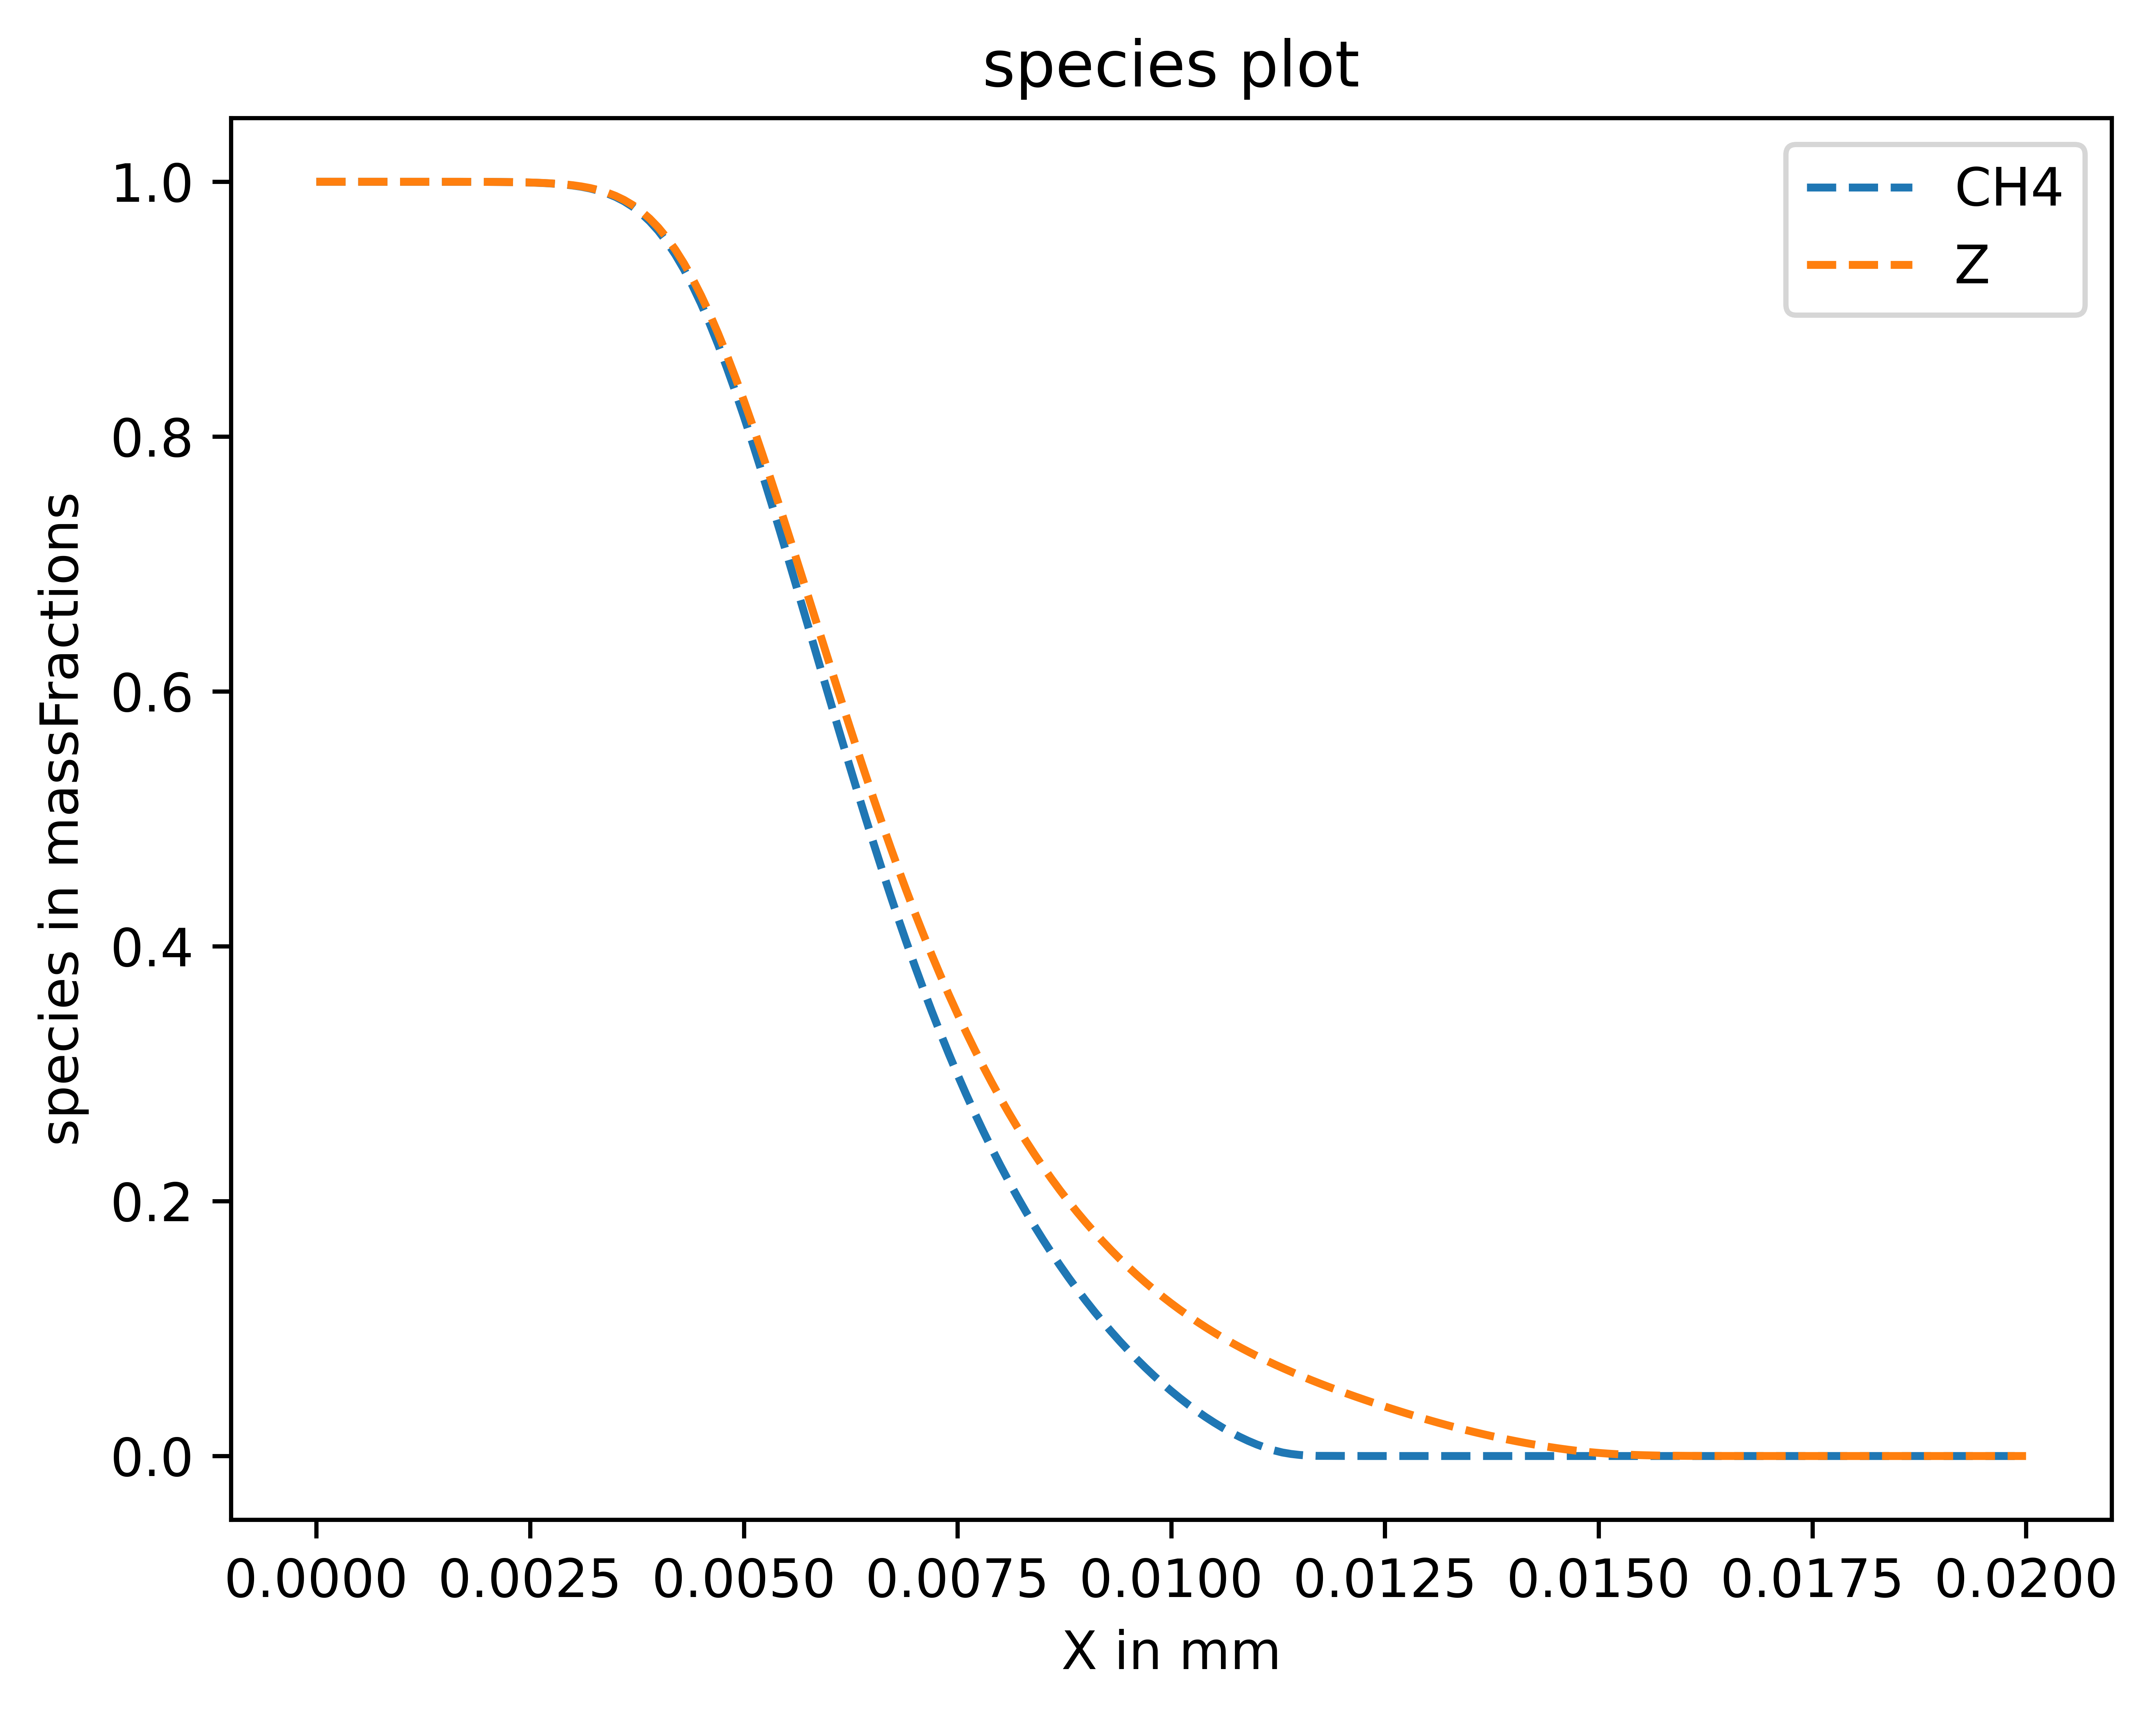

In [33]:
line = fields.sample_over_line((0,0,0),(0.02,0,0),resolution=1000) 
line
fig, ax = plt.subplots()
fig.set_dpi(1000)


ax.plot(line.points[:,0],line['CH4'],label='CH4',linestyle='--')
ax.plot(line.points[:,0],line['Z'],label='Z',linestyle='--')


ax.set_xlabel('X in mm')
ax.set_ylabel('species in massFractions')
ax.set_title('species plot')

ax.legend()

This accesses the spatial coordinates of the sampled points on the line,the points are the part of data structures in 3D coordinates (X,Y,Z).

In [23]:
print(line.points)
print(line.points[:,0])

[[0.000e+00 0.000e+00 0.000e+00]
 [2.000e-05 0.000e+00 0.000e+00]
 [4.000e-05 0.000e+00 0.000e+00]
 ...
 [1.996e-02 0.000e+00 0.000e+00]
 [1.998e-02 0.000e+00 0.000e+00]
 [2.000e-02 0.000e+00 0.000e+00]]
[0.000e+00 2.000e-05 4.000e-05 ... 1.996e-02 1.998e-02 2.000e-02]


Profiles of several species along the line

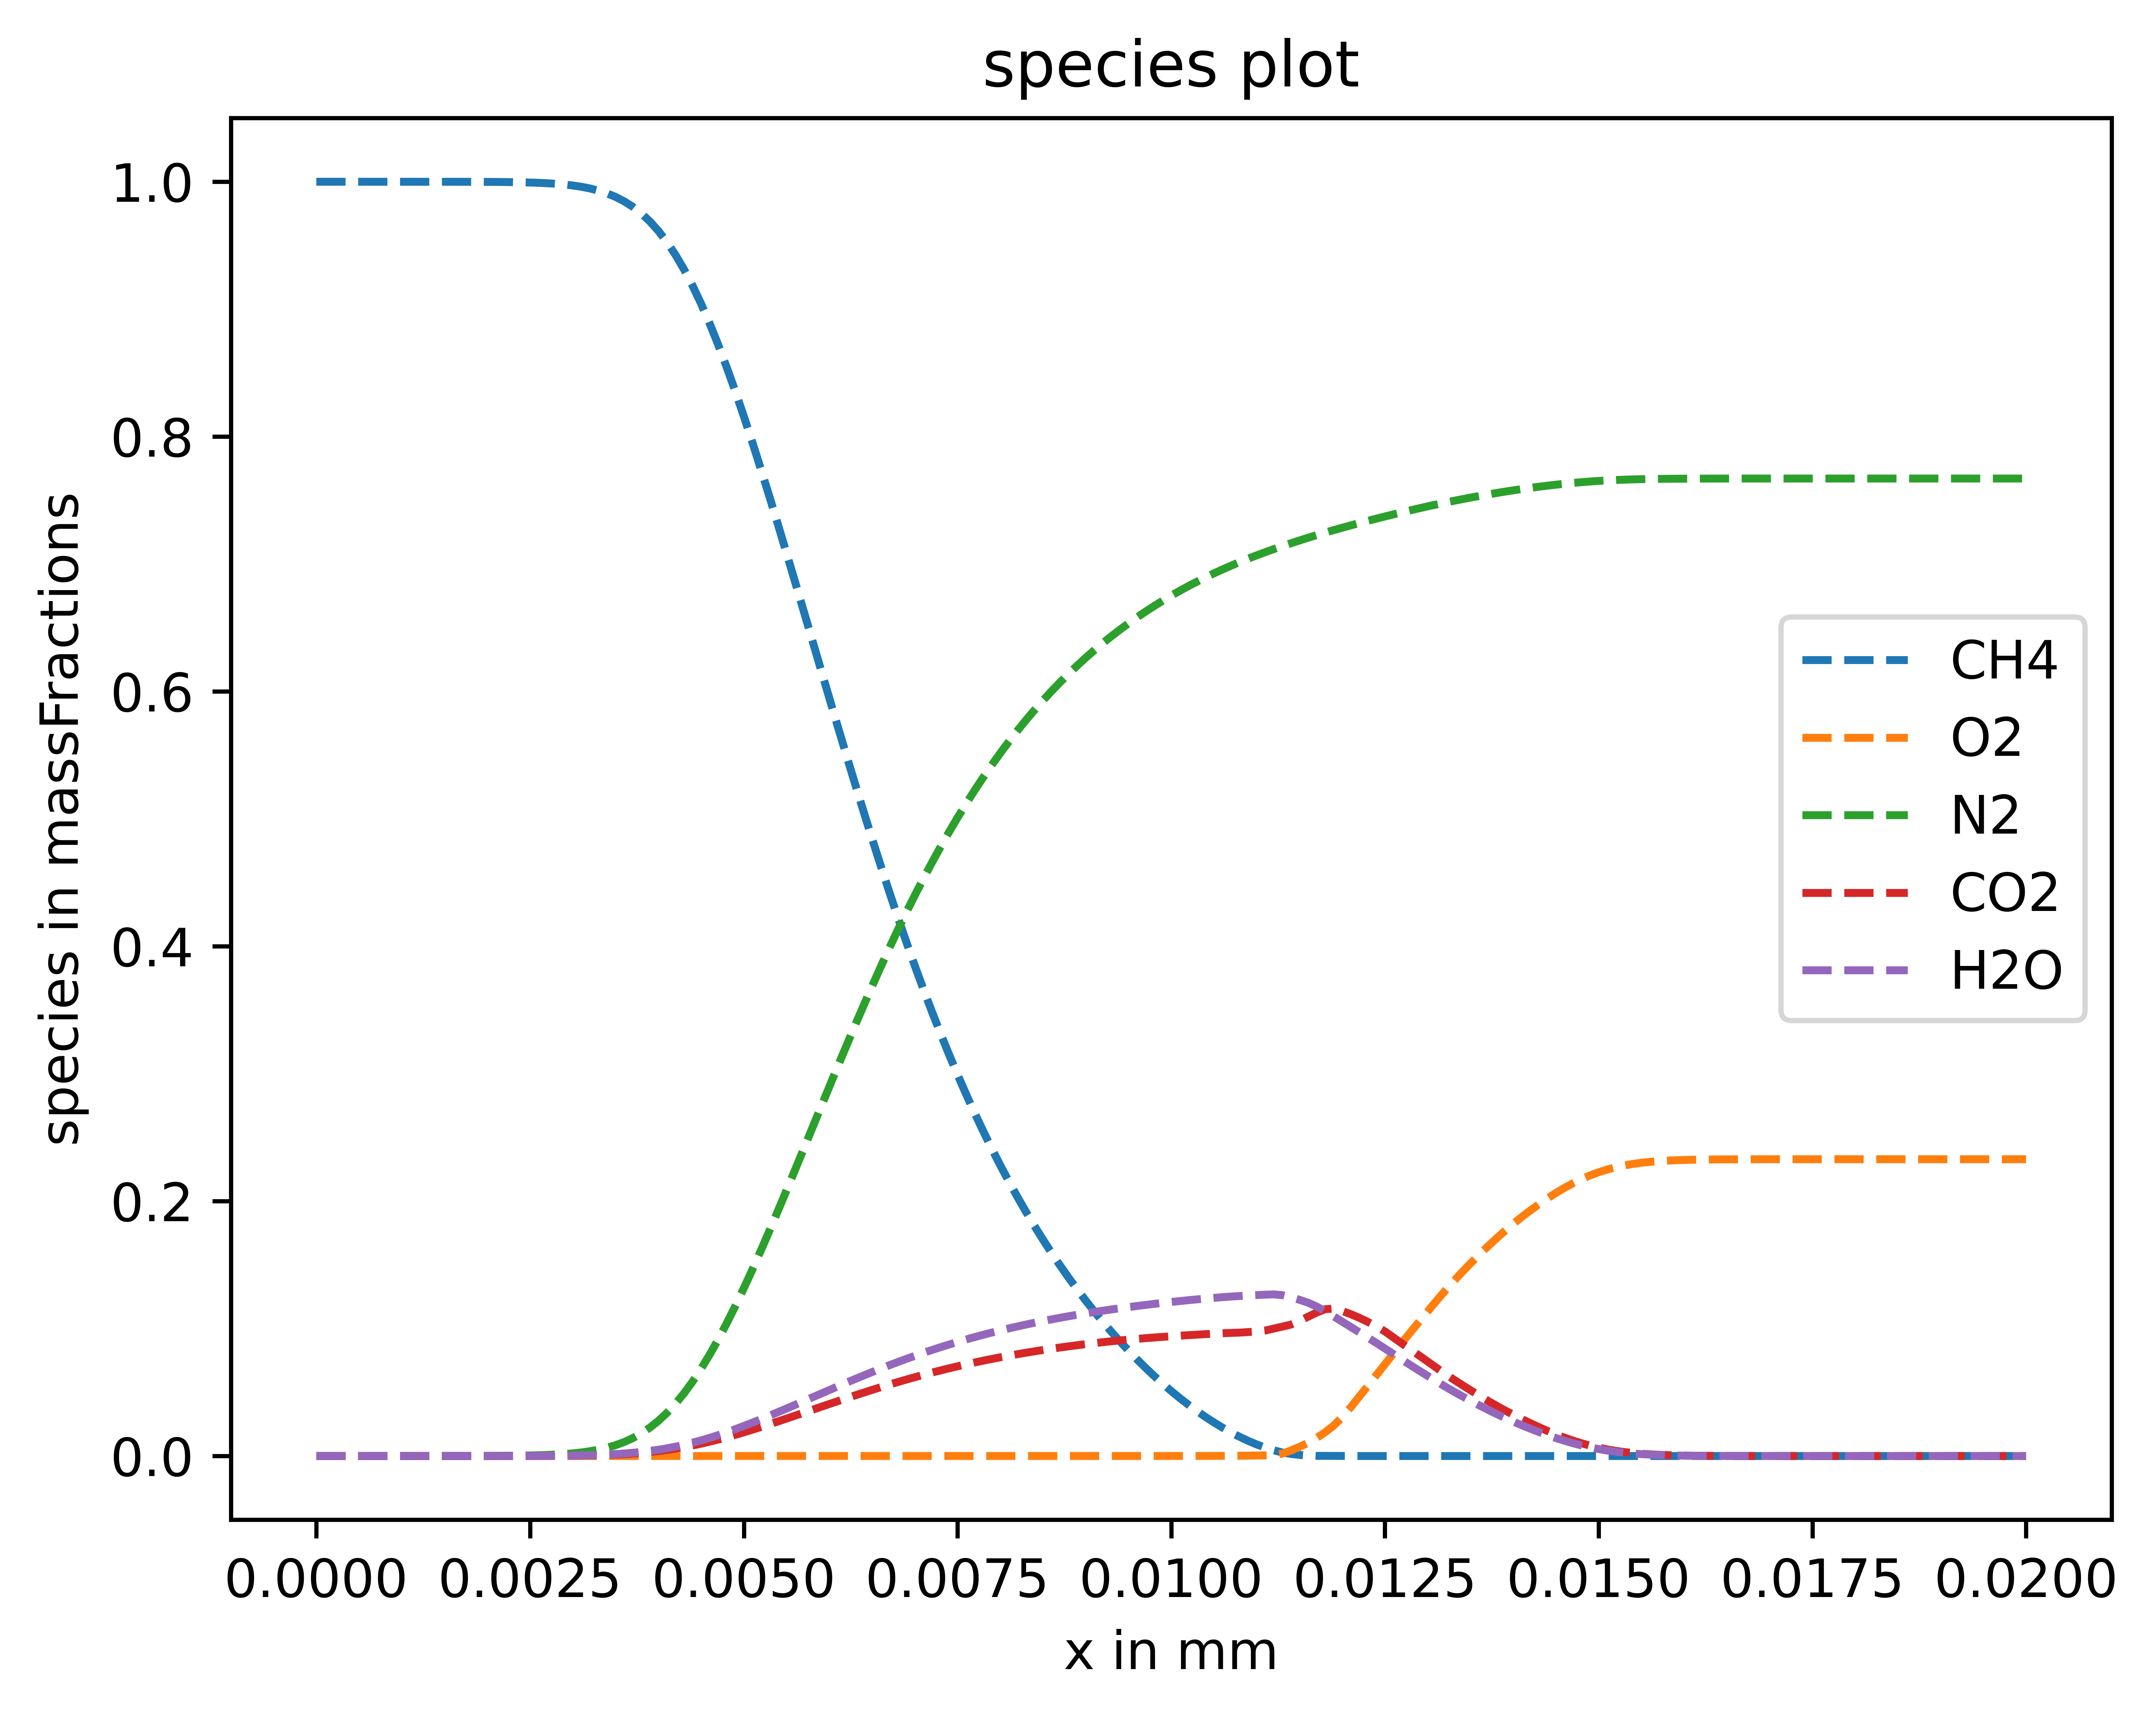

In [35]:
fig, ax = plt.subplots()
fig.set_dpi(1000)


ax.plot(line.points[:,0],line['CH4'],label='CH4',linestyle='--')
ax.plot(line.points[:,0],line['O2'],label='O2',linestyle='--')
ax.plot(line.points[:,0],line['N2'],label='N2',linestyle='--')
ax.plot(line.points[:,0],line['CO2'],label='CO2',linestyle='--')
ax.plot(line.points[:,0],line['H2O'],label='H2O',linestyle='--')
ax.set_xlabel('x in mm')
ax.set_ylabel('species in massFractions')
ax.set_title('species plot')

ax.legend()

Temperature profile (T) along the line

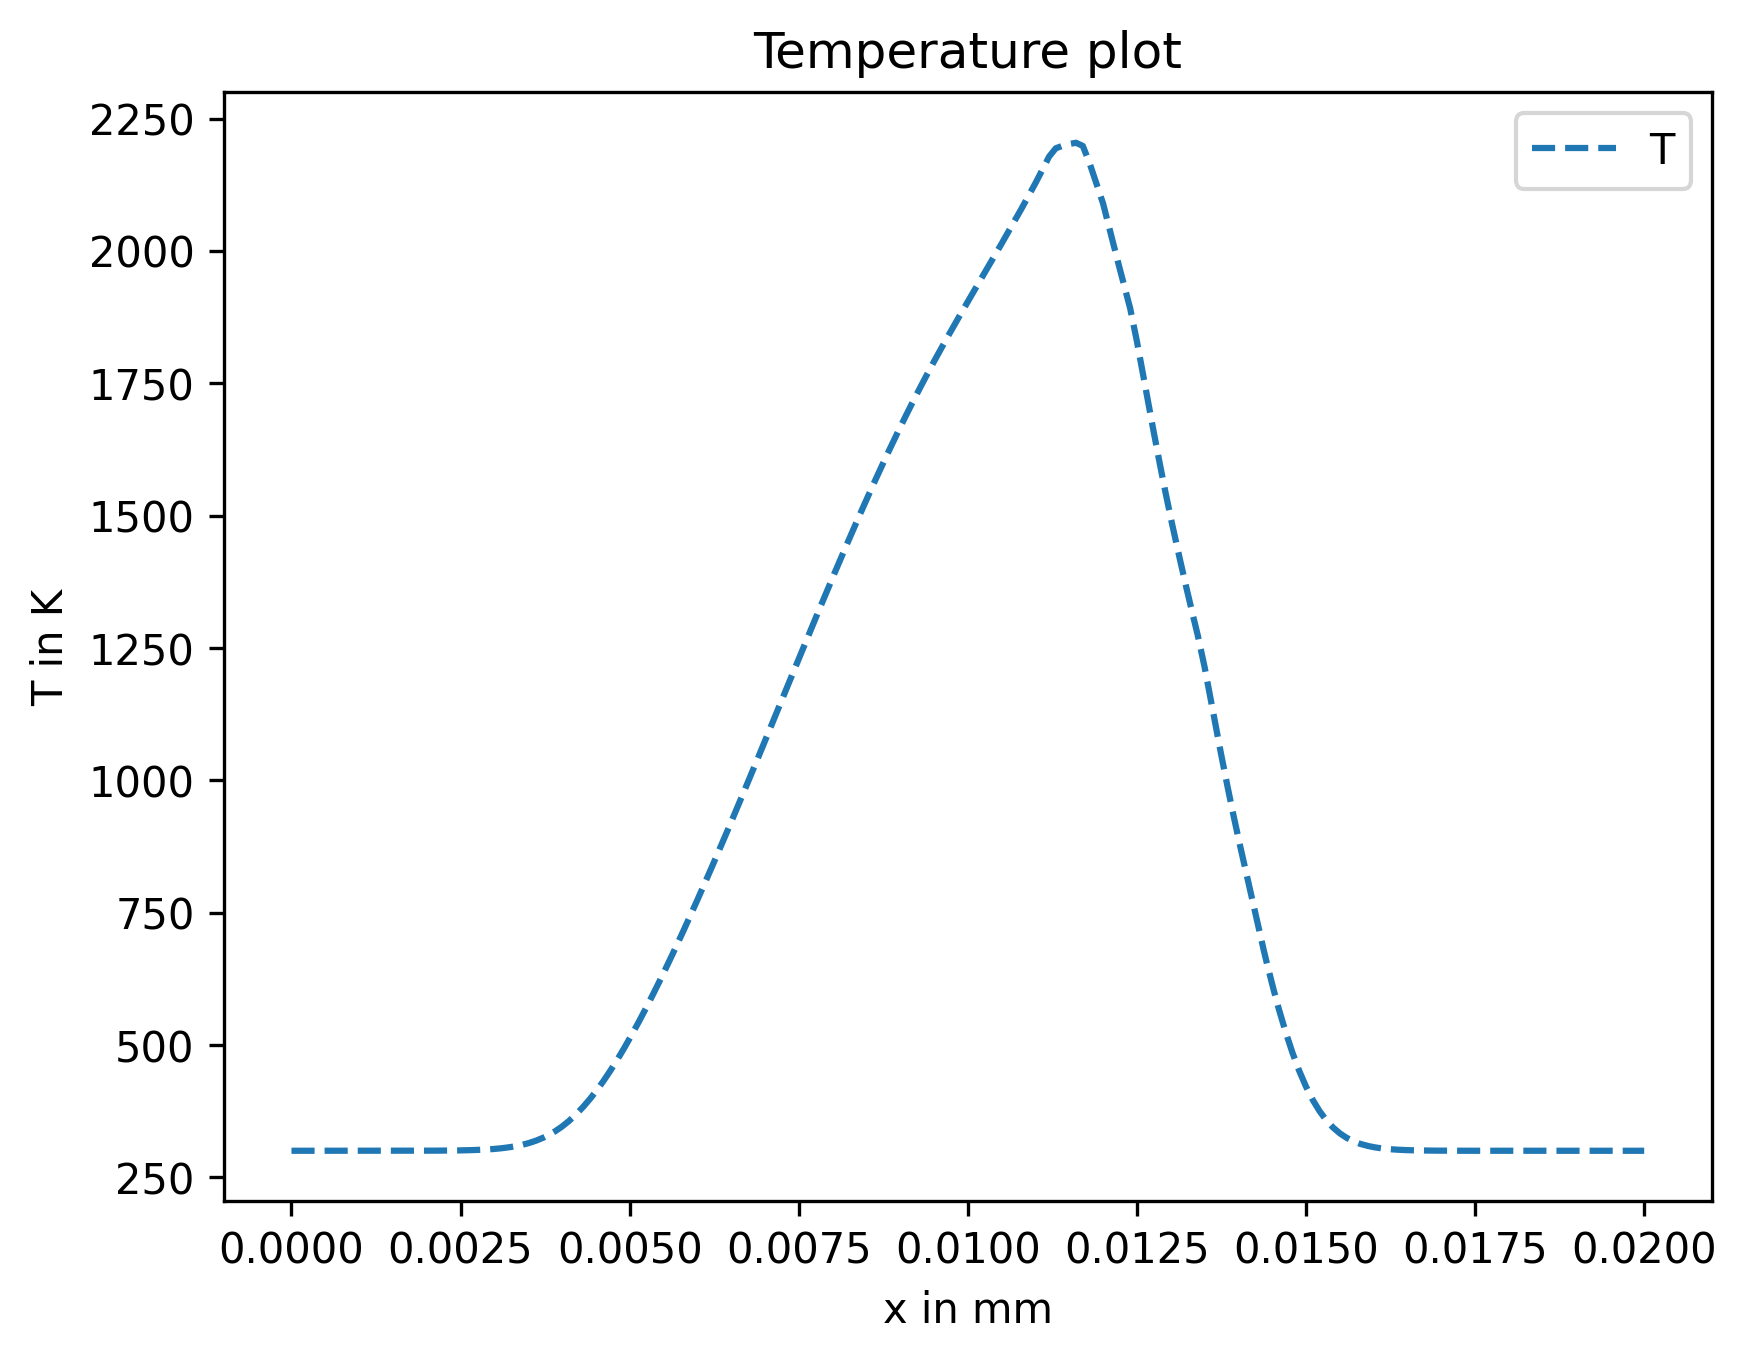

In [39]:
fig, ax = plt.subplots()
fig.set_dpi(300)


ax.plot(line.points[:,0],line['T'],label='T',linestyle='--')
ax.set_xlabel('x in mm')
ax.set_ylabel('T in K')
ax.set_title('Temperature plot')

ax.legend()

In [40]:
slice = fields.slice((0,0,1),(0,0,0)) 
slice

PolyData (0x7f6ed006ce80)
  N Cells:    16000
  N Points:   16281
  N Strips:   0
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   -1.000e-02, 1.000e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   32

/tmp/ipykernel_15923/575101869.py:14: UserWarning: The following kwargs were not used by contour: 'triangles'
  tricont = ax.tricontourf(pts[:,0], pts[:,1],


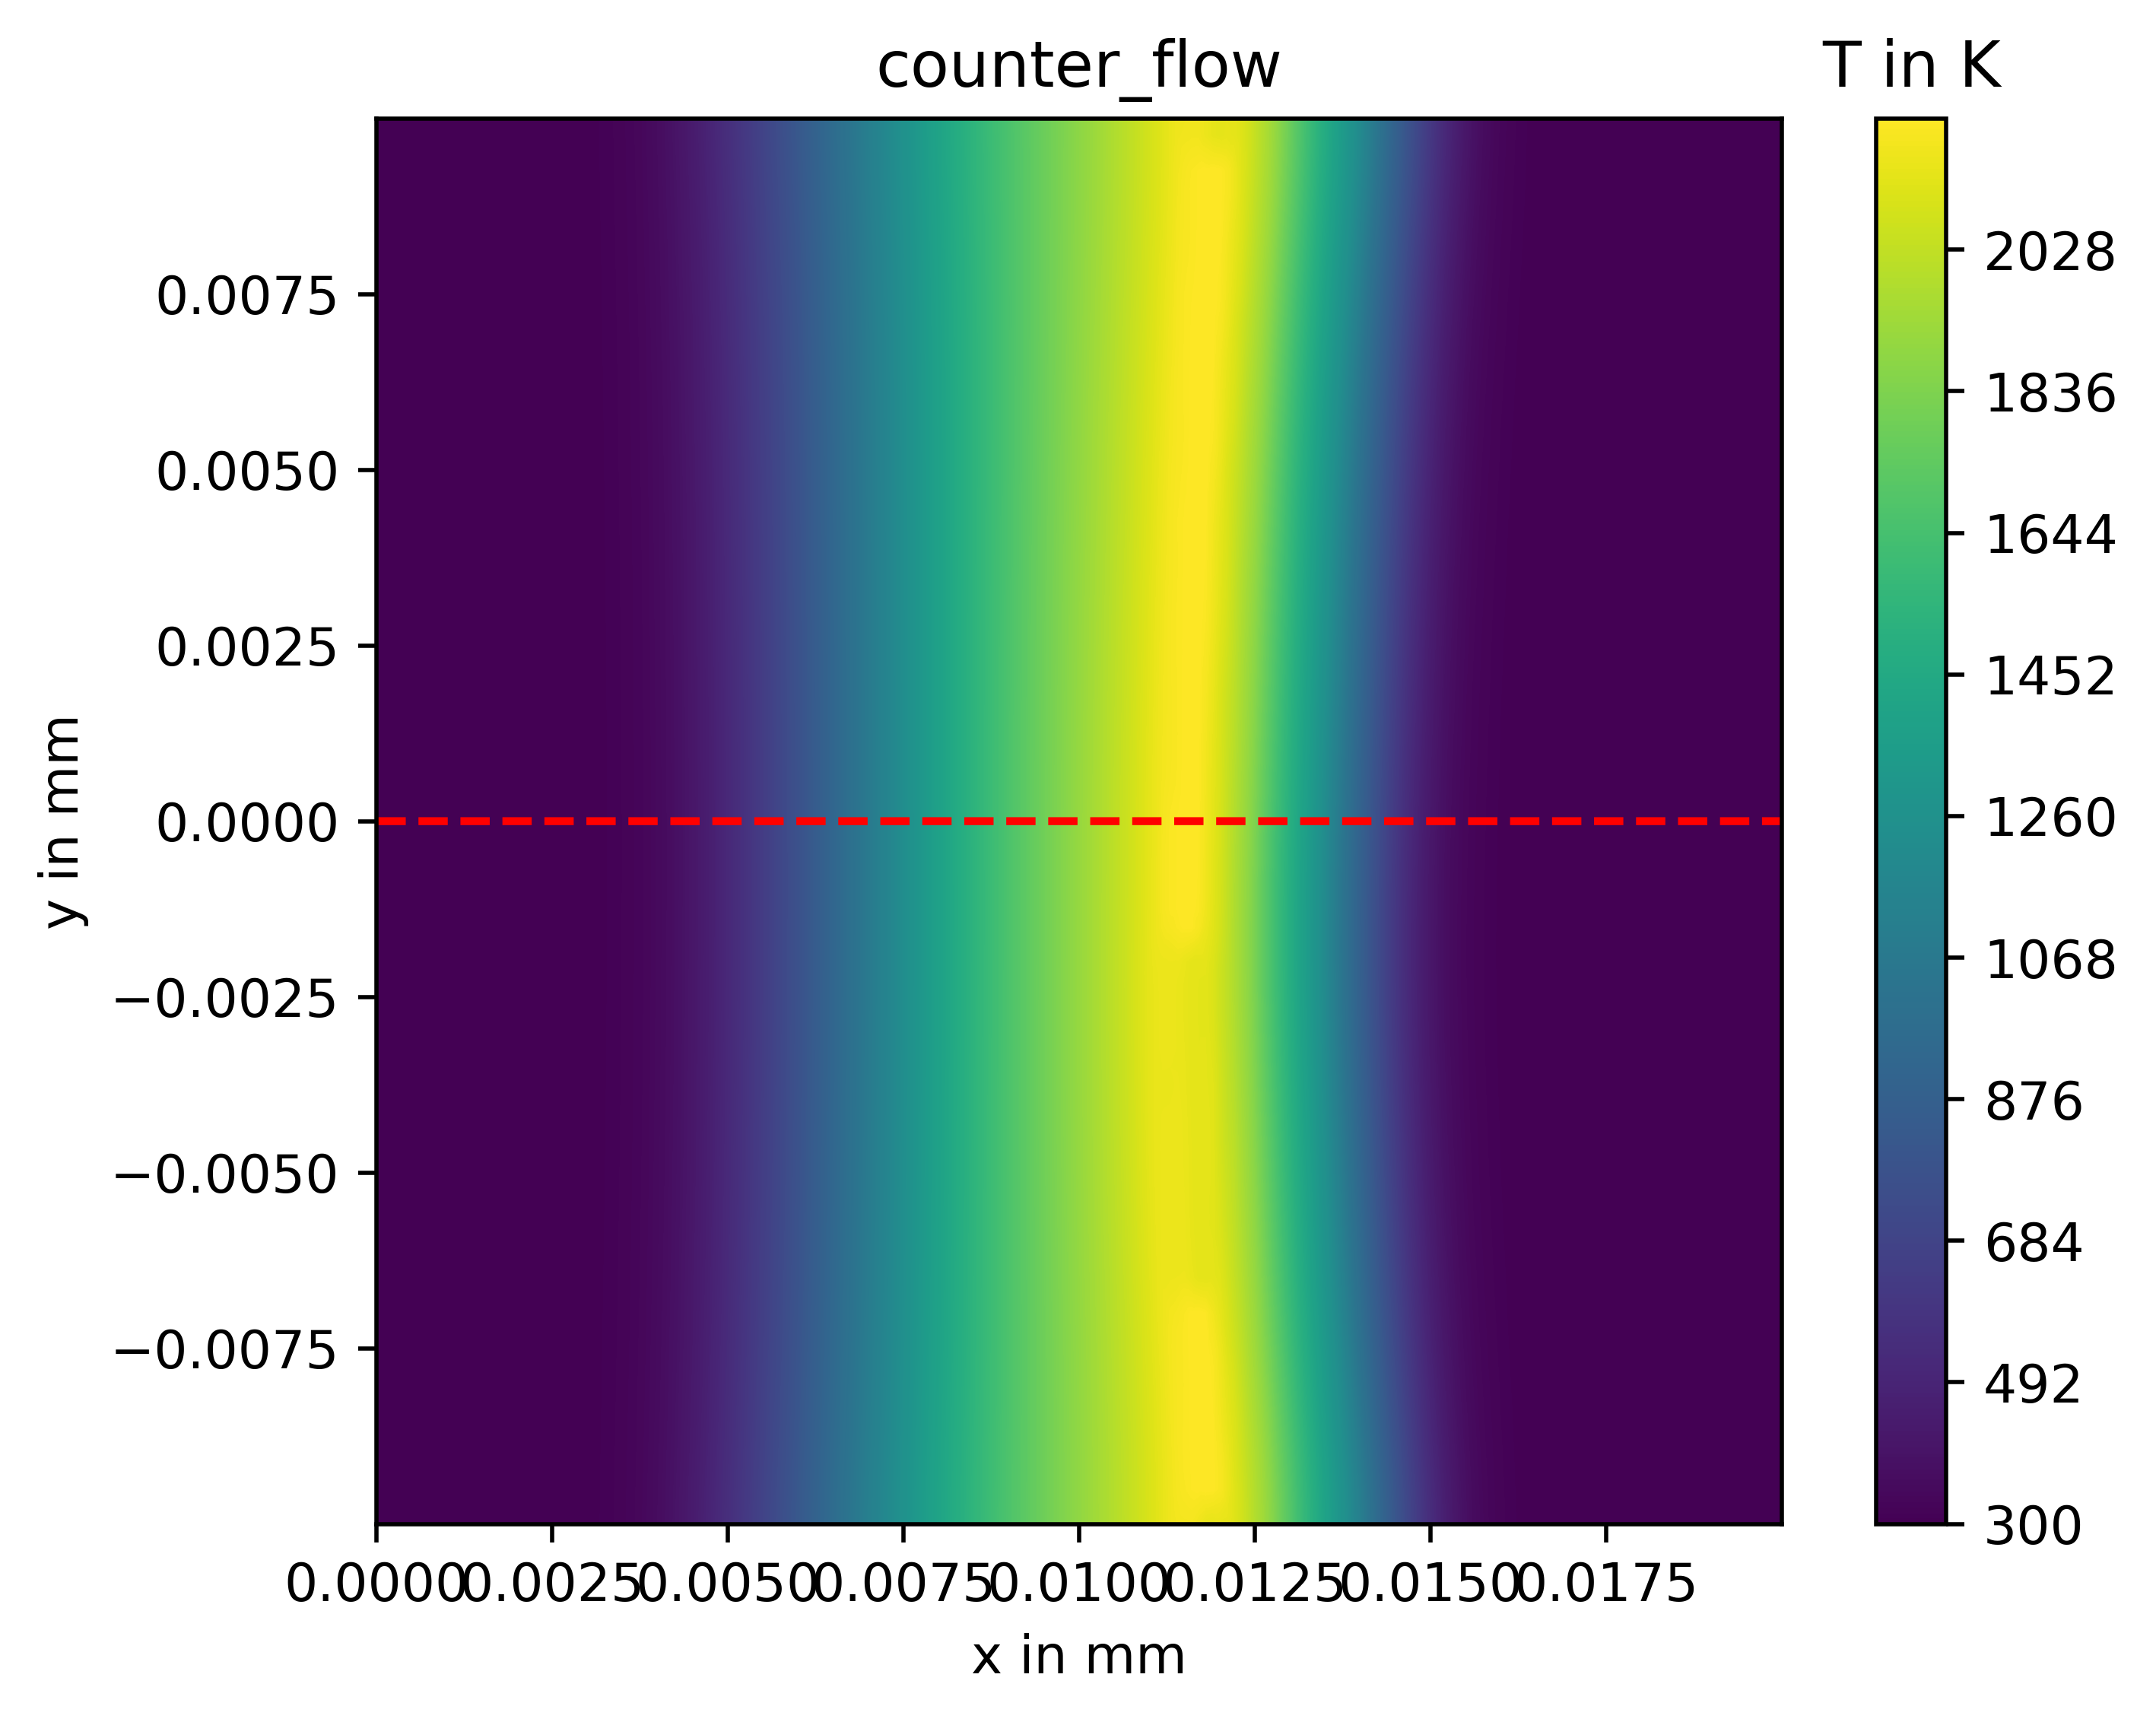

In [41]:
fig, ax = plt.subplots()
fig.set_dpi(500)

plt_slice = slice.cell_data_to_point_data()
plt_slice = plt_slice.triangulate()

pts = plt_slice.points
tri = plt_slice.faces.reshape((-1,4))[:,0:]

val = plt_slice['T']



tricont = ax.tricontourf(pts[:,0], pts[:,1],  
                    val,
                    triangles=tri, 
                    levels=1000,
                    )
ax.set_aspect('equal')
ax.set_xlabel('x in mm')
ax.set_ylabel('y in mm')
ax.set_title('counter_flow')
cb = fig.colorbar(tricont)
cb.ax.set_title(label='T in K')
line = fields.sample_over_line((0,0,0),(0.02,0,0))
ax.plot(line.points[:, 0], line.points[:, 1], color='red', markersize=0.25, linestyle='--')

To visualize it in 2D for understanding the distribution and behaviour, the code helps.

/tmp/ipykernel_15923/3029874280.py:12: UserWarning: The following kwargs were not used by contour: 'triangles'
  tricont = ax.tricontourf(pts[:,0], pts[:,1],


Text(0.5, 1.0, 'PV')

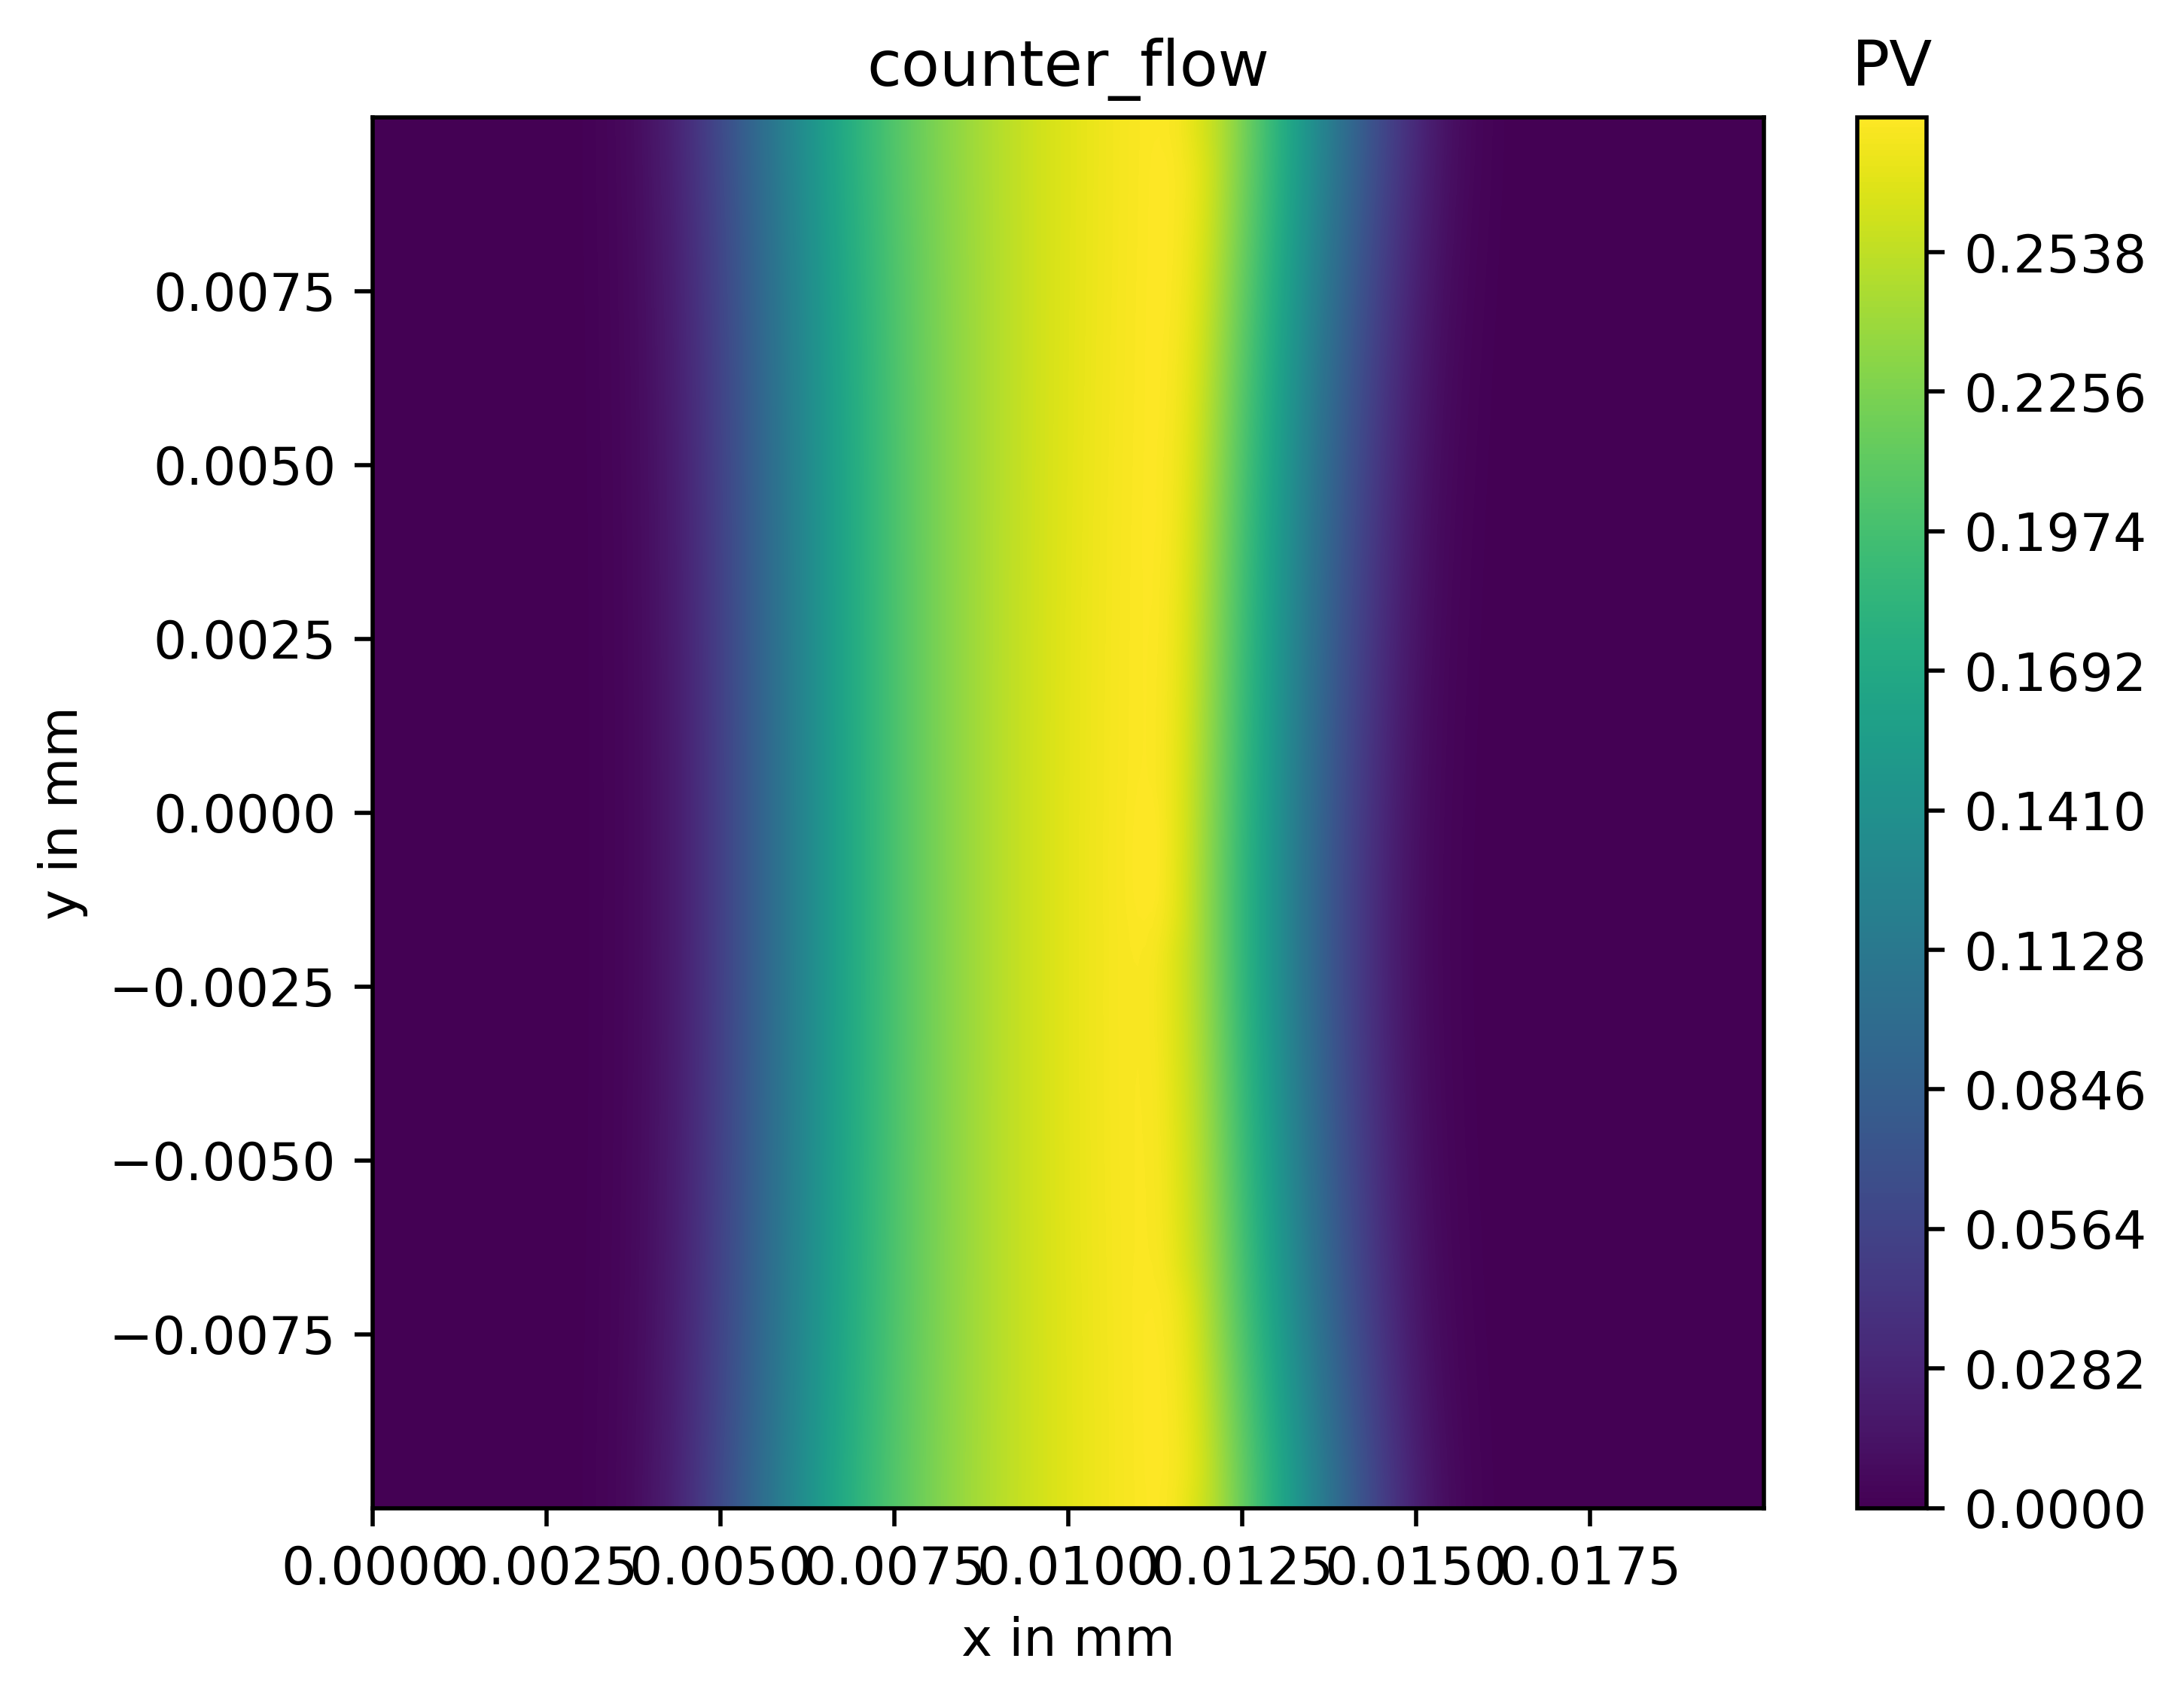

In [42]:
fig, ax = plt.subplots()
fig.set_dpi(500)

plt_slice = slice.cell_data_to_point_data()
plt_slice = plt_slice.triangulate()

pts = plt_slice.points
tri = plt_slice.faces.reshape((-1,4))[:,2:]

val = plt_slice['PV']

tricont = ax.tricontourf(pts[:,0], pts[:,1],  
                    val,
                    triangles=tri, 
                    levels=1000,
                    )
ax.set_aspect('equal')
ax.set_xlabel('x in mm')
ax.set_ylabel('y in mm')
ax.set_title('counter_flow')
cb = fig.colorbar(tricont)
cb.ax.set_title(label='PV')

## Finally, the Counterflow case for both Tabulated and Detailed Chemistry is obtained successfully.

# Comparison of tabulated and detailed chemistry results

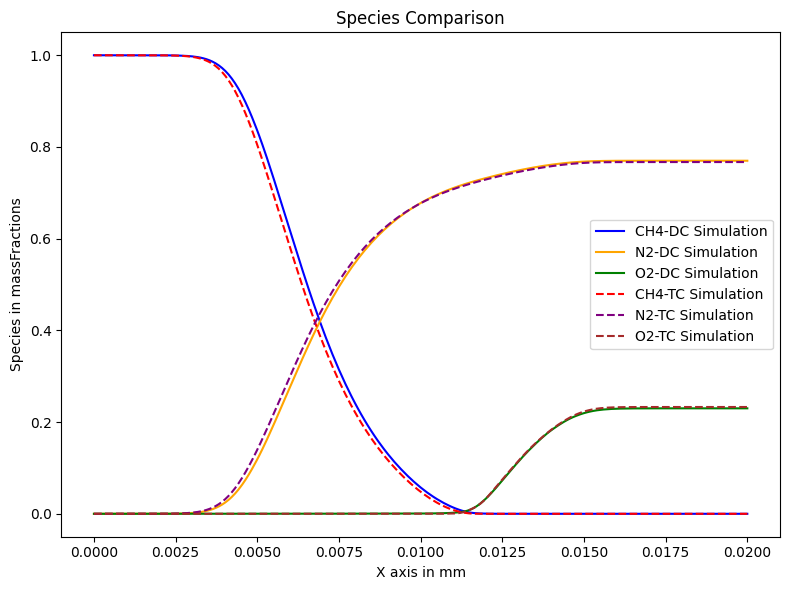

In [20]:
import pyvista as pv
import matplotlib.pyplot as plt

# Load the DC data
dc_reader = pv.POpenFOAMReader('/WORK_OF/skota/counterFlowFlame2D_cluster/foam.foam') 
dc_reader.case_type = 'reconstructed'
dc_reader.set_active_time_value(0.25)
dc_fields = dc_reader.read()['internalMesh']

# Load the TC data
tc_reader = pv.POpenFOAMReader('//WORK_OF/pnammi/counter_flow2D/counterflow/counterflow/cf_tc.foam')
tc_reader.case_type = 'reconstructed'
tc_reader.set_active_time_value(0.25)
tc_fields = tc_reader.read()['internalMesh']

# Extract species data along the specified line for DC
dc_line = dc_fields.sample_over_line((0, 0, 0), (0.02, 0, 0), resolution=1000)

# Extract species data along the specified line for TC
tc_line = tc_fields.sample_over_line((0, 0, 0), (0.02, 0, 0), resolution=1000)

# Create a figure for plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Plot DC species with different line styles
ax.plot(dc_line.points[:, 0], dc_line['CH4'], label='CH4-DC Simulation', linestyle='-', color='blue')
ax.plot(dc_line.points[:, 0], dc_line['N2'], label='N2-DC Simulation', linestyle='-', color='orange')
ax.plot(dc_line.points[:, 0], dc_line['O2'], label='O2-DC Simulation', linestyle='-', color='green')

# Plot TC species with different line styles
ax.plot(tc_line.points[:, 0], tc_line['CH4'], label='CH4-TC Simulation', linestyle='--', color='red')
ax.plot(tc_line.points[:, 0], tc_line['N2'], label='N2-TC Simulation', linestyle='--', color='purple')
ax.plot(tc_line.points[:, 0], tc_line['O2'], label='O2-TC Simulation', linestyle='--', color='brown')

ax.set_xlabel('X axis in mm')
ax.set_ylabel('Species in massFractions')
ax.set_title('Species Comparison')
ax.legend()

plt.tight_layout()
plt.show()


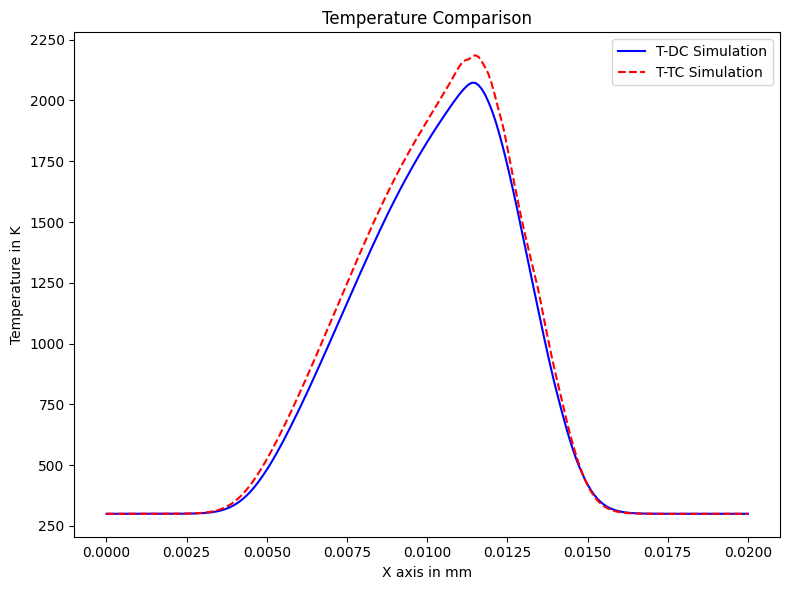

In [10]:
import pyvista as pv
import matplotlib.pyplot as plt

# Load the DC data
dc_reader = pv.POpenFOAMReader('/WORK_OF/skota/counterFlowFlame2D_cluster/foam.foam') 
dc_reader.case_type = 'reconstructed'
dc_reader.set_active_time_value(0.25)
dc_fields = dc_reader.read()['internalMesh']

# Load the TC data
tc_reader = pv.POpenFOAMReader('//WORK_OF/pnammi/counter_flow2D/counterflow/counterflow/cf_tc.foam')
tc_reader.case_type = 'reconstructed'
tc_reader.set_active_time_value(0.25)
tc_fields = tc_reader.read()['internalMesh']

# Extract temperature data along the specified line for DC
dc_line = dc_fields.sample_over_line((0, 0, 0), (0.02, 0, 0), resolution=1000)

# Extract temperature data along the specified line for TC
tc_line = tc_fields.sample_over_line((0, 0, 0), (0.02, 0, 0), resolution=1000)

# Create a figure for plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Plot DC temperature with a solid line
ax.plot(dc_line.points[:, 0], dc_line['T'], label='T-DC Simulation', linestyle='-', color='blue')

# Plot TC temperature with a dashed line
ax.plot(tc_line.points[:, 0], tc_line['T'], label='T-TC Simulation', linestyle='--', color='red')

ax.set_xlabel('X axis in mm')
ax.set_ylabel('Temperature in K')
ax.set_title('Temperature Comparison')
ax.legend()

plt.tight_layout()
plt.show()
